In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from architecture.config import Config

In [2]:
predictions = Config().predictions()

if not predictions.exists():
    raise FileNotFoundError(predictions, "Does not exist yet, generate a prediction by running the pipeline first.")

df = pd.read_csv(predictions).dropna()

history = df[~df["forecast"]]
forecast = df[df["forecast"]]

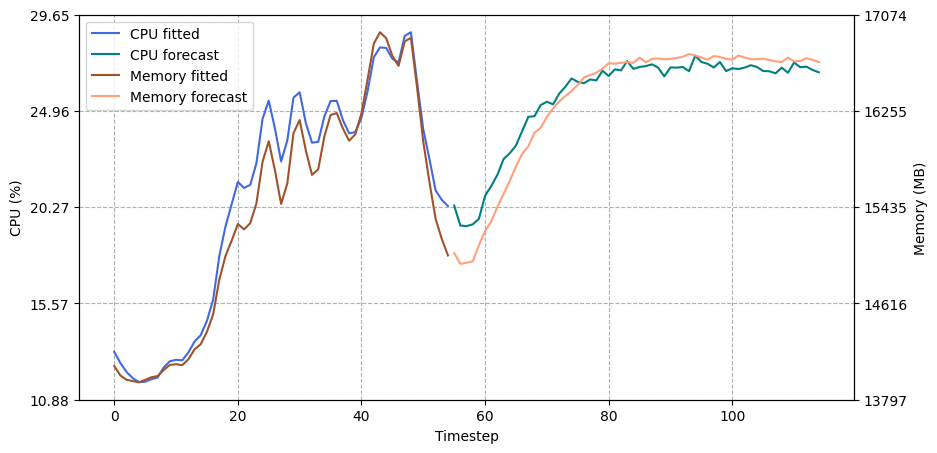

In [3]:
fig, ax_cpu = plt.subplots(figsize=(10, 5))
ax_mem = ax_cpu.twinx()

ax_cpu.plot(history["timestep"], history["cpu"], color="royalblue", label="CPU fitted")
ax_cpu.plot(forecast["timestep"], forecast["cpu"], color="teal", label="CPU forecast")
ax_mem.plot(history["timestep"], history["memory"], color="sienna", label="Memory fitted")
ax_mem.plot(forecast["timestep"], forecast["memory"], color="lightsalmon", label="Memory forecast")

ax_cpu.set_xlabel("Timestep")
ax_cpu.set_ylabel("CPU (%)")
ax_mem.set_ylabel("Memory (MB)")

ax_cpu.set_yticks(np.linspace(*ax_cpu.get_ylim(), 5))
ax_mem.set_yticks(np.linspace(*ax_mem.get_ylim(), 5))

lines = ax_cpu.get_lines() + ax_mem.get_lines()
ax_cpu.legend(lines, [line.get_label() for line in lines])
ax_cpu.grid(linestyle="--")
plt.show()